# M09 Overview | ONNX Runtime: QDQ ONNX and the Rewrites at Session Creation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m09_onnx_runtime/00_overview.ipynb)

M08 followed Route A of the [M07 overview](../m07_representation_lowering/00_overview.ipynb): ExecuTorch fixes the int8 kernels **when it exports the `.pte`**. This chapter follows Route B: the Q/DQ graph is exported as an `.onnx` and handed to ONNX Runtime (ORT). The file contains only standard Q/DQ ops; swapping in int8 kernels does not happen until ORT **creates the session**.

The first half of the M07 overview covered which layer ORT, the Execution Provider (EP), and MLAS each sit in. This chapter answers three questions:

| Question | One-line answer | notebook |
|---|---|---|
| What does a Q/DQ graph become when exported to ONNX? | Same structure; each op is replaced by its standard ONNX op (QDQ format) | M09-1 |
| At which step does ORT swap in int8 kernels? | At session creation, in QDQ node fusion starting at `ORT_ENABLE_EXTENDED` | M09-2 |
| How does ORT's own quantization tool differ from PT2E? | It does the same job, but writes more decisions into the file | M09-3 |

`onnx`, `onnxscript`, and `onnxruntime` are main dependencies of this project; no separate install is needed.

In [1]:
#| include: false
# On Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m09_onnx_runtime")

In [2]:
#| echo: false
import tempfile
from pathlib import Path

import numpy as np
import onnx
import onnxruntime as ort
import torch
from torch.export import Dim

from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.data import calibration_batches
from common.models import example_inputs, get_model
from common.viz import draw_onnx

quiet()
_ = torch.manual_seed(0)

## A First Example: conv + relu Through the Whole Path

The smallest conv + relu, from a PyTorch model to running in ORT. Below we use only the raw PyTorch, torchao, and ONNX Runtime APIs, in three steps.

**Step 1: PT2E, giving the Q/DQ graph.** Same as M05-1: `export_module` enables dynamic batch, and the quantizer is torchao's test-version XNNPACKQuantizer (M08-1).

In [3]:
model = get_model("conv_relu").eval()
x = example_inputs()                                            # batch 2

prepared = prepare_pt2e(export_module(model, x), get_xnnpack_quantizer(is_per_channel=True)[0])
with torch.no_grad():
    for batch in calibration_batches(64):
        prepared(*batch)
qdq = convert_pt2e(prepared)                                    # Q/DQ graph

**Step 2: Export to QDQ ONNX.** `torch.onnx.export` re-runs `torch.export` on `x`, so dynamic batch has to be stated again via `dynamic_shapes` (M09-1 C):

In [4]:
program = torch.onnx.export(qdq, x, dynamo=True, verbose=False, dynamic_shapes=({0: Dim("batch")},))
assert program is not None
onnx_model = program.model_proto                                # saving this gives the .onnx

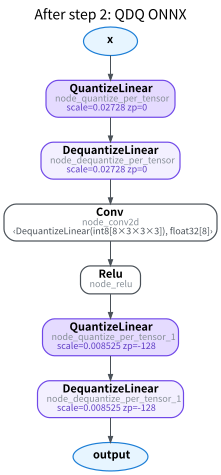

In [5]:
#| echo: false
draw_onnx(onnx_model, title="After step 2: QDQ ONNX")

It is identical to the Q/DQ graph, just renamed: `quantize_per_tensor` → `QuantizeLinear`, `conv2d` → `Conv`. `Conv` is still an fp32 op; the file itself contains no int8 kernel.

**Step 3: ORT creates the session and runs.** `SessionOptions.graph_optimization_level` picks the optimization level; we also set `optimized_model_filepath`, so ORT saves the rewritten graph and we can see what it did:

In [6]:
so = ort.SessionOptions()
so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_EXTENDED
with tempfile.TemporaryDirectory() as d:
    so.optimized_model_filepath = str(Path(d) / "optimized.onnx")
    session = ort.InferenceSession(onnx_model.SerializeToString(), so, providers=["CPUExecutionProvider"])
    rewritten = onnx.load(so.optimized_model_filepath)
y = np.asarray(session.run(None, {session.get_inputs()[0].name: torch.randn(5, 3, 16, 16).numpy()})[0])
print("Output shape for batch 5:", y.shape)

Output shape for batch 5: (5, 8, 16, 16)


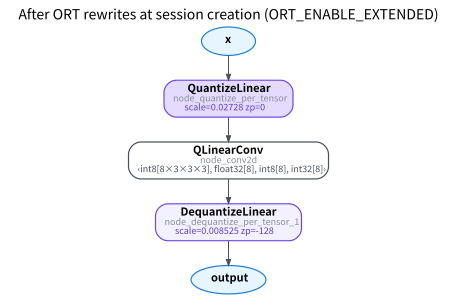

In [7]:
#| echo: false
draw_onnx(rewritten, title="After ORT rewrites at session creation (ORT_ENABLE_EXTENDED)")

"DequantizeLinear → Conv → Relu → QuantizeLinear" has been replaced by a single `QLinearConv`: its inputs and outputs are int8, computed by the CPU EP's int8 kernel. The file did not change; ORT swapped it.

The later notebooks use a few wrappers from this project (`common/onnx_utils.py`; none of them are torch or ORT APIs):

| Wrapper | What it does |
|---|---|
| `xnnpack_qdq(model, x)` | Step 1 |
| `to_onnx(gm, x)` | Step 2, with `dynamic_shapes` by default |
| `ort_session(onnx_model, level)` | Session creation from step 3, always on the CPU EP |
| `optimized_model(onnx_model, level)` | Step 3's save-then-reload, giving the rewritten graph |
| `ort_quantize(fp32_onnx, ...)` | ORT's own quantization tool `quantize_static` (M09-3) |

## The Five Graph Optimization Levels

This section summarizes the ORT v1.30.0 source so the conclusions are not limited to the TinyConvNet model. The official Graph Optimizations page lists only four levels and does not mention QDQ node fusion, so it lags behind the source; below, the source is authoritative, and the parts measured on macOS arm64 with ORT 1.30.0 point to the corresponding notebook.

`GraphOptimizationLevel` has five values, which `abi_session_options.cc` maps to ORT's internal `TransformerLevel`:

| API level | Value | Internal Level |
|---|---|---|
| `ORT_DISABLE_ALL` | 0 | `Default` |
| `ORT_ENABLE_BASIC` | 1 | `Level1` |
| `ORT_ENABLE_EXTENDED` | 2 | `Level2` |
| `ORT_ENABLE_LAYOUT` | 3 | `Level3` |
| `ORT_ENABLE_ALL` | 99 | `MaxLevel` (= `Level4`) |

Each level includes all the rewrites of the previous one. When unspecified, `InferenceSession` uses `ORT_ENABLE_ALL`.

In [8]:
print({name: int(level) for name, level in ort.GraphOptimizationLevel.__members__.items()})

{'ORT_DISABLE_ALL': 0, 'ORT_ENABLE_BASIC': 1, 'ORT_ENABLE_EXTENDED': 2, 'ORT_ENABLE_LAYOUT': 3, 'ORT_ENABLE_ALL': 99}


### The Order at Session Creation

```text
Load the .onnx
  → Required steps       always run, regardless of level
  → Level1 (BASIC)       before EP assignment: independent of the EP
  → Assign EPs           each node is given to one EP
  → Level2 to Level4     after EP assignment: mostly only for specific EPs
  → Insert Cast, Memcpy  required steps
```

Level1 runs before EP assignment, so it applies to every EP; for the rewrites from Level2 on, the source mostly lists the EPs they apply to (`inference_session.cc`, `graph_transformer_utils.cc`).

### What Each Level Adds

| Level | What it adds | Measured |
|---|---|---|
| `ORT_DISABLE_ALL` | Required steps: expand ONNX functions, `EnsureUniqueDQForNodeUnit` (copy a DQ that feeds several ops), insert Cast/Memcpy | M09-2: an extra `/duplicated` DQ |
| `ORT_ENABLE_BASIC` | EP-independent simplification: remove redundant nodes, constant folding, Conv+BN/Add/Mul fusion; QDQ preprocessing: `WeightBiasQuantization` (quantize bias to int32) | M09-2: int32 bias = round(b / (s_x·s_w)) |
| `ORT_ENABLE_EXTENDED` | QDQ node fusion; `ReluQuantFusion`, `ClipQuantFusion`; fp32 fusions (Conv+activation → `FusedConv`, Transformer-style Attention, LayerNorm, etc.) | M09-2: `QLinearConv`, Relu disappears |
| `ORT_ENABLE_LAYOUT` | CPU layout: `NhwcTransformer` (int8 `QLinearConv`, fp16 Conv, etc. become NHWC); `NchwcTransformer` (fp32 Conv, x86-64 only) | M09-2: `QLinearConv` becomes NHWC |
| `ORT_ENABLE_ALL` | `FuseFp16InitializerToFp32NodeTransformer`: fp16 constants to fp32 | M09-2: same as LAYOUT |

Three details:

- BASIC's constant folding **skips DQ** on QDQ models, preserving the "DQ → op → Q" unit for Level2 to fuse (source comment).
- `ReluQuantFusion` applies only when the zero point of the QuantizeLinear after the Relu equals the type's lower bound (-128 for int8, 0 for uint8), and only on the CPU EP. In that case Q's clamp already does the Relu's job (M09-2).
- LAYOUT switches to NHWC because the CPU EP's int8 conv kernel computes only in NHWC: every run of an NCHW `QLinearConv` converts each image to NHWC inside the kernel and back to NCHW afterwards (`qlinearconv.cc`). `NhwcTransformer` lifts the transposes into the graph, adjacent Transposes that cancel each other are then removed, and the whole int8 segment transposes only once at each end (M09-2).

### The Three Groups of QDQ Node Fusion

`qdq_selector_action_transformer.cc` groups ops (M09-2's TinyConvNet measures Conv, Add, Gemm, MaxPool, Reshape, and ReduceMean; the other ops are from reading the source only):

| Group | Examples | Result |
|---|---|---|
| Replaced by an int8 op | Conv, MatMul, Gemm, Add, Mul, Concat, Sigmoid, Softmax | `QLinear*` / `com.microsoft.QGemm` |
| Q/DQ removed | MaxPool, Reshape, Transpose, Flatten | The original op runs directly on int8 |
| Not on the list | ReduceMean | Stays in fp32, with one int8 ↔ fp32 conversion before and after |

`com.microsoft.*` ops are defined by ORT itself and are not in the ONNX standard.

### Platform-Dependent

For the same `.onnx`, the graph rewritten on x86 differs from arm (from reading the source; neither point was measured on x86):

- **int8 or uint8**: the default of `QDQIsInt8Allowed()` is allowed on arm and not allowed on other platforms. When not allowed, Level2 first runs `QDQS8ToU8Transformer`, turning int8 activations into uint8.
- **NCHWc**: `NchwcTransformer` requires `MlasNchwcGetBlockSize() > 1`, which holds only on x86-64.

When ORT saves an optimized graph at a level above EXTENDED, it prints a warning: the graph may contain hardware-specific optimizations and can only be used in the same environment. So to compare rewrite results, create the session on the target machine and look there.

## Comparison with M08

| | M08 (ExecuTorch) | M09 (ONNX Runtime) |
|---|---|---|
| Deployment file | `.pte` | `.onnx` |
| When the kernel is decided | At export (partitioner) | At session creation (EP + optimization level) |
| Who recognizes `dq → op → q` | XNNPACK delegate | ORT's QDQ node fusion (from EXTENDED) |
| fp32 bias | Quantized to int32 during lowering | Quantized to int32 at session creation (BASIC) |
| CPU int8 kernel | XNNPACK | MLAS (CPU EP) |
| Dynamic batch | This course uses static shape | Give `dynamic_shapes` at export and any batch runs |

Neither output is guaranteed to match the Q/DQ graph bit for bit, for the reason given in the M08 overview, "Numerical Differences from the Q/DQ Graph"; when comparing, follow the M07 overview, "Rules Before Comparing Backends".

## CPU vs. VPU/NPU (Leading into M10)

The CPU EP in this chapter is very permissive: it accepts per-channel, asymmetric activations, and dynamic batch, and an op with no int8 version simply stays in fp32. VPU/NPU-class hardware is usually much narrower (a general statement; not verified on real hardware in this project):

| Constraint | CPU EP (this chapter) | Typical VPU/NPU |
|---|---|---|
| Activation quantization | per-tensor affine | Often requires per-tensor symmetric |
| scale | Any fp32 | Sometimes must be a power of 2 (implemented with a shift) |
| Supported ops | Wide; unsupported ones stay in fp32 | Narrow; unsupported ones must fall back to CPU |
| shape | Dynamic batch is fine | Mostly requires static shape |

M10 uses PT2E's Quantizer API to write these constraints as a custom backend, then checks whether the Q/DQ graph complies and falls back to CPU for ops outside the list.

## Summary and Chapter Map

- QDQ ONNX is backend-neutral: the file contains only standard Q/DQ ops, and whether they become int8 kernels is decided at run time by the EP and the optimization level.
- The five levels divide the work: DISABLE_ALL does only the required preparation, BASIC does EP-independent simplification and bias quantization, EXTENDED does QDQ node fusion, LAYOUT changes the layout, and ALL adds only fp16 handling.
- Which ops can become int8 follows a fixed list; the layout level depends on the CPU architecture.

| notebook | Question it answers |
|---|---|
| [M09-1 Exporting QDQ ONNX](01_onnx_qdq_export.ipynb) | What each PT2E op becomes in ONNX; what the file stores; dynamic batch |
| [M09-2 ORT's Five Levels](02_ort_qdq_fusion.ipynb) | What TinyConvNet is rewritten into at each level; int32 bias; why Relu disappears |
| [M09-3 ORT's Quantization Tool](03_ort_quant_compare.ipynb) | `quantize_static` vs PT2E; QDQ format vs QOperator format |

Deliberately skipped in this chapter: EPs other than CPU (the XNNPACK EP is not in the pip build of ORT; how EPs such as Core ML partition the graph was not looked up); bit-for-bit comparison of ORT outputs against the Q/DQ graph, and latency.

## References

- ONNX Runtime docs: [Graph Optimizations](https://onnxruntime.ai/docs/performance/model-optimizations/graph-optimizations.html), [Quantize ONNX models](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html), [Execution Providers](https://onnxruntime.ai/docs/execution-providers/)
- ORT v1.30.0 source ([GitHub](https://github.com/microsoft/onnxruntime/tree/v1.30.0)):
  - `include/onnxruntime/core/session/onnxruntime_c_api.h`: definition of `GraphOptimizationLevel`
  - `onnxruntime/core/session/abi_session_options.cc`: level → `TransformerLevel`
  - `onnxruntime/core/session/inference_session.cc`: session creation order, required steps
  - `onnxruntime/core/optimizer/graph_transformer_utils.cc`: the transformers registered at each Level
  - `onnxruntime/core/optimizer/qdq_transformer/selectors_actions/qdq_selector_action_transformer.cc`: QDQ fusion list
  - `onnxruntime/core/optimizer/qdq_transformer/relu_quantizelinear.cc`: `ReluQuantFusion`
  - `onnxruntime/core/optimizer/nhwc_transformer.cc`: NHWC op list
  - `onnxruntime/core/providers/cpu/quantization/qlinearconv.cc`: int8 conv kernel, transposes internally for NCHW
- PyTorch docs: [torch.onnx](https://docs.pytorch.org/docs/stable/onnx.html)